In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("cleaned.csv", delimiter=',' ,encoding='latin-1')

In [3]:
print(df.head())
print(df.info())
print(df.describe())

print("\nPuuduvad väärtused:")
print(df.isna().sum())



           dateCrawled                                               name  \
0  2016-03-14 12:52:21                     Jeep_Grand_Cherokee_"Overland"   
1  2016-03-17 16:54:04                                GOLF_4_1_4__3TÃRER   
2  2016-03-31 17:25:20                     Skoda_Fabia_1.4_TDI_PD_Classic   
3  2016-04-04 17:36:23  BMW_316i___e36_Limousine___Bastlerfahrzeug__Ex...   
4  2016-04-01 20:48:51                        Peugeot_206_CC_110_Platinum   

   seller  price abtest vehicleType  yearOfRegistration    gearbox  powerPS  \
0  privat   9800   test         suv                2004  automatik      163   
1  privat   1500   test  kleinwagen                2001    manuell       75   
2  privat   3600   test  kleinwagen                2008    manuell       69   
3  privat    650   test   limousine                1995    manuell      102   
4  privat   2200   test      cabrio                2004    manuell      109   

     model  kilometer  monthOfRegistration fuelType       bran

In [32]:

import re
import unicodedata
from collections import Counter, defaultdict

import pandas as pd


# Ilmselgelt mitte mudelinimed.
BAD_START = {
    "andere", "sonstige", "sonstiges",
    "auto", "fahrzeug", "diesel", "benzin",
    "tuv", "tuev", "rot",
    "kombi", "cabrio", "kleinwagen",
    "sportwagen", "sportwagon",
    "sommerfahrzeug", "autoverkauf",
    "gebrauchte", "gebraucht",
    "wegen", "mit", "ich", "meine", "alles",
    "in", "guenstiger", "zuverlaessiges",
    "schmucker", "sparsamer", "vollaustattung",
    "sonderangebot", "selespeed", "jts", "jtd",
    "sportliches",
}

# Mootori-, varustuse- ja muud lisatähised,
# mis ei peaks eraldi mudelikategooriat tekitama.
BAD_WORDS = BAD_START | {
    "jtdm", "tdi", "tsi", "cdi", "hdi", "dci",
    "fsi", "gdi", "ts", "twin", "spark",
    "kw", "ps", "hp", "aut", "automatik",
    "automatic", "leder", "junior",
    "quadrifogli", "selespeed",
    "sport", "line", "comfortline",
    "trendline", "highline", "sline",
    "avant",
    "grau", "rot", "schwarz", "weiss",
    "silber", "blau", "gruen", "braun",
    "gelb", "beige", "metallic",
}

COLORS = {
    "grau", "rot", "schwarz", "weiss",
    "silber", "blau", "gruen", "braun",
    "gelb", "beige", "metallic",
}


def normalize_text(value):
    """Muudab teksti ühtsele kujule."""
    if pd.isna(value):
        return ""

    value = str(value).casefold()
    value = unicodedata.normalize("NFKD", value)
    value = "".join(
        char for char in value
        if not unicodedata.combining(char)
    )
    value = value.replace("ß", "ss")
    value = re.sub(r"[^a-z0-9]+", " ", value)

    return " ".join(value.split())


def compact(value):
    """Eemaldab tühikud, et kirjapildi variante võrrelda."""
    return re.sub(r"[^a-z0-9]", "", value)


def format_model(value):
    """Ühtlustab mudelinime kirjapildi."""
    value = normalize_text(value)

    # C 200 -> C200
    value = re.sub(
        r"\b([a-z])\s+(\d+)\b",
        r"\1\2",
        value
    )

    # 328 i -> 328i
    value = re.sub(
        r"\b(\d+)\s+([a-z])\b",
        r"\1\2",
        value
    )

    return value


def strip_brand(model, brand):
    """Eemaldab mudelinime ette sattunud automargi."""
    model_parts = model.split()
    brand_parts = brand.split()

    # Näiteks: alfa romeo 147 -> 147
    if brand_parts and model_parts[:len(brand_parts)] == brand_parts:
        return " ".join(model_parts[len(brand_parts):])

    # Näiteks: alfa 156sw -> 156sw
    if brand_parts and model_parts and model_parts[0] == brand_parts[0]:
        return " ".join(model_parts[1:])

    # Näiteks: alfaromeogtv -> gtv
    model_key = compact(model)
    brand_key = compact(brand)

    if brand_key and model_key.startswith(brand_key):
        return model_key[len(brand_key):]

    return model


def is_model_code(key):
    """Tunneb ära tüüpilise mudelikoodi kuju."""
    return bool(
        re.fullmatch(r"\d{2,3}", key)
        or re.fullmatch(r"\d{1,3}[a-z]", key)
        or re.fullmatch(r"[a-z]\d{1,3}[a-z]?", key)
    )


def is_bad_candidate(display):
    """Kontrollib, kas väärtus sobib mudelinimeks."""
    if not display:
        return True

    tokens = display.split()

    if tokens[0] in BAD_START:
        return True

    if len(tokens) > 2:
        return True

    if any(token in BAD_WORDS for token in tokens):
        return True

    if any(
        re.fullmatch(r"\d+(kw|ps|hp)", token)
        for token in tokens
    ):
        return True

    return False


def clean_car_models(
    df,
    brand_col="brand",
    model_col="clean_model",
    output_col="clean_model_2",
    min_frequency=15
):
    """
    Puhastab automaatselt kõigi automarkide mudelinimed.

    Tagastab:
        cleaned_df: DataFrame koos puhastatud mudelite veeruga.
        unknowns: tabel väärtustest, mida ei suudetud tuvastada.
    """

    prepared = []
    frequencies = Counter()
    forms = defaultdict(Counter)

    # 1. Normaliseerime kõik väärtused.
    for brand, model in zip(df[brand_col], df[model_col]):

        brand_norm = normalize_text(brand)
        model_norm = normalize_text(model)

        model_norm = strip_brand(model_norm, brand_norm)

        brand_key = compact(brand_norm)
        model_key = compact(model_norm)
        display = format_model(model_norm)

        prepared.append((brand_key, model_key, display))

        if model_key:
            frequencies[(brand_key, model_key)] += 1
            forms[(brand_key, model_key)][display] += 1

    # 2. Koostame iga margi mudelikataloogi.
    candidates = defaultdict(dict)

    for (brand, key), count in frequencies.items():

        display = forms[(brand, key)].most_common(1)[0][0]
        tokens = display.split()

        # Säilitame haruldased mudelinimed,
        # millele järgneb ainult värvinimetus.
        if (
            len(tokens) == 2
            and tokens[1] in COLORS
            and re.fullmatch(r"[a-z]{4,}", tokens[0])
            and tokens[0] not in BAD_START
        ):
            candidates[brand].setdefault(
                compact(tokens[0]), tokens[0]
            )

        if is_bad_candidate(display):
            continue

        # Mudel lisatakse, kui see on piisavalt sage
        # või näeb välja nagu tüüpiline mudelikood.
        is_single_word_name = (
            len(tokens) == 1
            and re.fullmatch(r"[a-z]{4,}", tokens[0])
        )

        if (
            count >= min_frequency
            or is_model_code(key)
            or is_single_word_name
        ):
            candidates[brand][key] = display

    # 3. Sobitame kõik ülejäänud väärtused kataloogiga.
    cleaned_models = []

    for brand, key, display in prepared:

        if not key or not display:
            cleaned_models.append("unknown")
            continue

        # Ilmselge kuulutuse tekst.
        if display.split()[0] in BAD_START:
            cleaned_models.append("unknown")
            continue

        brand_candidates = candidates[brand]

        # Täpne vaste.
        if key in brand_candidates:
            cleaned_models.append(brand_candidates[key])
            continue

        # Tüüpiline haruldane mudelikood.
        if is_model_code(key):
            cleaned_models.append(display)
            continue

        # Pikemad mudelinimed enne lühemaid,
        # et näiteks GTV ei läheks GT alla.
        matched = None

        for candidate in sorted(
            brand_candidates,
            key=len,
            reverse=True
        ):
            if len(candidate) < 2:
                continue

            if not key.startswith(candidate):
                continue

            suffix = key[len(candidate):]

            # Väldime näiteks A4 sobitamist A40 külge.
            if (
                suffix
                and candidate[-1].isdigit()
                and suffix[0].isdigit()
            ):
                continue

            matched = brand_candidates[candidate]
            break

        cleaned_models.append(
            matched if matched is not None else "unknown"
        )

    # 4. Säilitame originaalandmed ja lisame uue veeru.
    result = df.copy()
    result[output_col] = cleaned_models

    # 5. Koostame ülevaate väärtustest, mida ei tuvastatud.
    unknowns = (
        result[result[output_col] == "unknown"]
        .groupby([brand_col, model_col], dropna=False)
        .size()
        .rename("count")
        .reset_index()
        .sort_values("count", ascending=False)
    )

    return result, unknowns

df, unknowns = clean_car_models(
    df,
    brand_col="brand",
    model_col="clean_model",
    min_frequency=15
)

print(df["clean_model_2"].value_counts())
print(unknowns.head(10))

clean_model_2
golf                      19667
unknown                    9728
a4                         8279
polo                       7972
passat                     7644
corsa                      7346
astra                      7231
a3                         5237
a6                         5155
focus                      4489
fiesta                     3609
touran                     2788
206                        2709
twingo                     2698
vectra                     2465
mondeo                     2305
zafira                     2299
clio                       2231
cooper                     2063
ibiza                      1967
c180                       1956
megane                     1952
fortwo                     1934
octavia                    1866
lupo                       1805
fabia                      1761
punto                      1720
c200                       1629
clk                        1520
c220                       1505
transporter               

In [5]:
pd.set_option('display.max_rows', None)

In [24]:
df.groupby('brand').model_final.value_counts()

brand          model_final        
alfa_romeo     147                      412
               156                      394
               159                      181
               unknown                  124
               spider                   110
               mito                     110
               gt                        87
               giulietta                 54
               166                       47
               brera                     30
               gtv                       27
               145                        5
               146                        5
               4c                         3
               other                      1
audi           a4                      8278
               a3                      5237
               a6                      5155
               tt                      1135
               a5                       941
               a1                       580
               a8                       4

In [7]:
# Loeme iga margi ja mudeli kombinatsiooni esinemissageduse
model_counts = df.groupby(
    ["brand", "clean_model_2"]
)["clean_model_2"].transform("size")

# Ühendame haruldased mudelid kategooriasse other
rare_models = (
    (model_counts < 3)
    & (df["clean_model_2"] != "unknown")
)

df["model_final"] = df["clean_model_2"]
df.loc[rare_models, "model_final"] = "other"

In [35]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=["price", "seller", "abtest", "name", "clean_model", "clean_model_2", "model", "dateCrawled"])

y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

In [36]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

Numeric: ['yearOfRegistration', 'powerPS', 'kilometer', 'monthOfRegistration', 'listingAge']
Categorical: ['vehicleType', 'gearbox', 'fuelType', 'brand', 'notRepairedDamage', 'model_final']


In [37]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="unknown"
    ))
])

In [38]:
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=20
    ))
])

In [39]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [40]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="median")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

In [41]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=50,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

In [42]:
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 1129.684062178859
RMSE: 2180.15618881694
R²: 0.9207811673882408


In [43]:
from sklearn.base import clone
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import ExtraTreesRegressor

models = {
    "Decision Tree": DecisionTreeRegressor(
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=50,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=50,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    )
}

results = []

for name, regressor in models.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("regressor", regressor)
    ])

    pipeline.fit(X_train, y_train)

    pred = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values("MAE"))

           Model          MAE         RMSE        R2
2    Extra Trees  1073.724166  2084.313292  0.927593
1  Random Forest  1129.684062  2180.156189  0.920781
0  Decision Tree  1365.363350  2596.798644  0.887609


In [44]:
print("Baseline MAE:",
      mean_absolute_error(y_test, baseline_predictions))

print("Random Forest MAE:",
      mean_absolute_error(y_test, predictions))

Baseline MAE: 4819.467523126411
Random Forest MAE: 1129.684062178859


In [45]:
errors = pd.DataFrame({
    "actual": y_test,
    "predicted": predictions
})

errors["absolute_error"] = abs(
    errors["actual"] - errors["predicted"]
)

print(
    errors.sort_values(
        "absolute_error",
        ascending=False
    ).head(20)
)

        actual     predicted  absolute_error
89165    99000   8939.684524    90060.315476
26847    84911   1498.984048    83412.015952
27707     9500  66318.877095    56818.877095
248026   69900  23433.873095    46466.126905
37774    63000  19959.565000    43040.435000
68530    13500  55782.438143    42282.438143
6186       647  39824.517333    39177.517333
45289    53500  15336.543333    38163.456667
219982   48500  12237.872333    36262.127667
236942   42500   6426.879667    36073.120333
97767    14750  50737.829381    35987.829381
80926    25000  60818.327048    35818.327048
2724     59999  24257.619905    35741.380095
12533    69999  35557.155333    34441.844667
228942   47500  17131.041524    30368.958476
100684    4800  34721.041000    29921.041000
221760   99900  70043.196762    29856.803238
111449   33500   3730.628667    29769.371333
99676     2500  32074.119667    29574.119667
225073   80900  51964.307667    28935.692333


                          feature  importance
0         num__yearOfRegistration    0.438499
1                    num__powerPS    0.350898
2                  num__kilometer    0.047223
48             cat__brand_porsche    0.027420
4                 num__listingAge    0.022274
3        num__monthOfRegistration    0.010299
12       cat__vehicleType_unknown    0.007284
11           cat__vehicleType_suv    0.005582
6         cat__vehicleType_cabrio    0.005306
18           cat__fuelType_diesel    0.005134
14           cat__gearbox_manuell    0.004277
23                cat__brand_audi    0.004264
42       cat__brand_mercedes_benz    0.004230
58          cat__brand_volkswagen    0.003701
13         cat__gearbox_automatik    0.003493
648  cat__model_final_transporter    0.003168
16           cat__fuelType_benzin    0.003129
61      cat__notRepairedDamage_ja    0.003078
24                 cat__brand_bmw    0.002754
5            cat__vehicleType_bus    0.002658


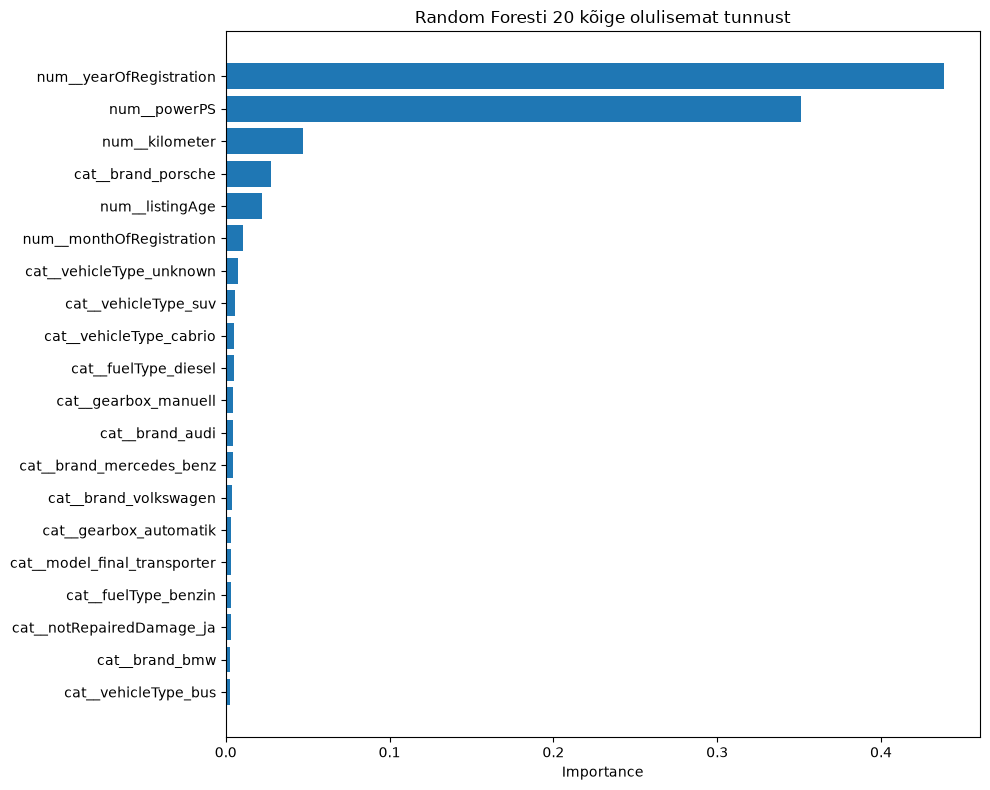

In [46]:
import pandas as pd
import matplotlib.pyplot as plt

# Võta mudelist eeltöödeldud tunnuste nimed
preprocessor = model.named_steps["preprocessor"]
regressor = model.named_steps["regressor"]

feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "feature": feature_names,
    "importance": regressor.feature_importances_
})

importance = importance.sort_values("importance", ascending=False)

print(importance.head(20))

# Joonista graafik
top_features = importance.head(20).sort_values("importance")

plt.figure(figsize=(10, 8))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Importance")
plt.title("Random Foresti 20 kõige olulisemat tunnust")
plt.tight_layout()
plt.show()

In [47]:
X_train_no_age = X_train.drop(columns=["listingAge"])
X_test_no_age = X_test.drop(columns=["listingAge"])

In [48]:
errors = pd.DataFrame({
    "actual": y_test,
    "predicted": predictions
})

errors["absolute_error"] = (
    errors["actual"] - errors["predicted"]
).abs()

errors["price_group"] = pd.cut(
    errors["actual"],
    bins=[0, 3000, 7000, 15000, 30000, float("inf")],
    labels=["0-3000", "3000-7000", "7000-15000",
            "15000-30000", "30000+"]
)

print(
    errors.groupby("price_group", observed=True)
    .agg(
        MAE=("absolute_error", "mean"),
        car_count=("actual", "count")
    )
)

                     MAE  car_count
price_group                        
0-3000        529.380078      20277
3000-7000     961.648498      13732
7000-15000   1491.472635      10531
15000-30000  2465.600013       4589
30000+       6053.018642        922


In [49]:
from sklearn.inspection import permutation_importance
import pandas as pd

# Kasutame 5000 testandmete rida, et analüüs ei oleks liiga aeglane
X_sample = X_test.sample(
    n=min(5000, len(X_test)),
    random_state=42
)
y_sample = y_test.loc[X_sample.index]
print(X_sample)
'''
result = permutation_importance(
    model,
    X_sample,
    y_sample,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance = pd.DataFrame({
    "feature": X_sample.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

print(importance)
'''

       vehicleType  yearOfRegistration    gearbox  powerPS  kilometer  \
219206         bus                2004    manuell      136     150000   
85462        kombi                2002    manuell      150     150000   
131117  kleinwagen                1998    manuell      101     150000   
131819         bus                2005    manuell      105     150000   
30133   kleinwagen                2004  automatik      140     150000   
66359    limousine                2001    manuell      115     150000   
53658   kleinwagen                2003    manuell       54      70000   
194706   limousine                2012  automatik      170      80000   
95216    limousine                1995    manuell      110     150000   
160684  kleinwagen                2000    manuell       54     150000   
12339          NaN                2016  automatik      150     150000   
93930   kleinwagen                2006    manuell       55     150000   
47222          suv                2013  automatik  

'\nresult = permutation_importance(\n    model,\n    X_sample,\n    y_sample,\n    scoring="neg_mean_absolute_error",\n    n_repeats=5,\n    random_state=42,\n    n_jobs=-1\n)\n\nimportance = pd.DataFrame({\n    "feature": X_sample.columns,\n    "importance": result.importances_mean\n}).sort_values("importance", ascending=False)\n\nprint(importance)\n'